# Cookie Cats A/B test: should the first gate move from level 30 to level 40?

**Rahul Jha, KinetiArc.** Independent analysis of a public dataset; not affiliated with Tactile Entertainment.

- **Decision: keep the gate at level 30.** Under the rule fixed before the analysis, gate_40 is significantly worse on D7 retention: 18.20% vs 19.02%, a gap of 0.82 percentage points (95% CI 0.31 to 1.33), or 4.3% lower in relative terms.
- **Trust warning: the 50/50 split is off** (sample ratio mismatch, p = 0.0086, below the 0.01 alarm level). The cause can't be diagnosed from this file. The imbalance alone would overturn the D7 result only if 784 of the 789 surplus players (99.4%) were non-retained, against 81.8% for a typical gate_40 player.
- **Blind spot: revenue.** The data has no revenue column, so this decision rests on retention only.

In [1]:
import sys, json
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cookiecats as cc

DATA_PATH = "data/cookie_cats.csv"   # Kaggle / DataCamp "Cookie Cats" file
SEED = 42
OUTLIER_CAP = 10_000                 # rounds in 14 days; above this is not human play

# Chart style: two fixed series colours, recessive grid, text in ink colours.
COLORS = {cc.CONTROL: "#2a78d6", cc.TREATMENT: "#eb6834"}
NEUTRAL = "#6250d6"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "xtick.color": MUTED, "ytick.color": MUTED, "ytick.left": False,
    "text.color": INK, "font.size": 10.5, "axes.titlesize": 11.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
})
pd.set_option("display.width", 120)
print("pandas", pd.__version__, "| numpy", np.__version__)


pandas 2.3.3 | numpy 2.0.2


## 1. The data

One row per player: 90,189 players, randomised at install to `gate_30` (44,700) or `gate_40` (45,489). Columns are player id, variant, rounds played in the first 14 days, and whether the player came back on day 1 and day 7.

Validation before any testing: no duplicate player ids, no empty cells and no unexpected variant labels. Two oddities are worth noting:

- 3,994 players logged 0 rounds, and of those 87 count as retained on D1 and 29 on D7. Coming back without playing a round is possible, but it may also be a logging quirk. The group is too small to change the result.
- 3,599 players were retained on D7 but not D1. That is expected, because retention here means returning on that specific day.

In [2]:
df = cc.load(DATA_PATH)
checks = cc.validate(df)
print(json.dumps(checks, indent=2))


{
  "rows": 90189,
  "columns": [
    "userid",
    "version",
    "sum_gamerounds",
    "retention_1",
    "retention_7"
  ],
  "duplicate_userids": 0,
  "null_cells": 0,
  "versions": {
    "gate_40": 45489,
    "gate_30": 44700
  },
  "unexpected_versions": [],
  "rounds_min": 0,
  "rounds_max": 49854,
  "zero_round_players": 3994,
  "zero_round_retained_d1": 87,
  "zero_round_retained_d7": 29,
  "d7_without_d1": 3599
}


In [3]:
df.head()


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 2. Sample ratio mismatch: the first check, and it fails

A sample ratio mismatch (SRM) test asks whether the arms are the size randomisation should have produced. gate_30 received 49.56% of players against an intended 50%. The chi-square test gives 6.90, p = 0.0086, which is below the 0.01 alarm level used for this check.

A share that close to 50% looks harmless, but at this sample size it is unlikely to be chance. Possible causes are an assignment bug, logging loss in one arm, or bot filtering applied unevenly. This file has no install dates or device data, so none of these can be confirmed or ruled out. Every comparison below carries this caveat, and section 3 measures how much it could matter.

In [4]:
srm = cc.srm_test(checks["versions"][cc.CONTROL], checks["versions"][cc.TREATMENT])
print(f"gate_30: {srm['n_control']:,}  gate_40: {srm['n_treatment']:,}  "
      f"control share {srm['control_share']:.3%}")
print(f"chi-square = {srm['chi2']:.2f}, p = {srm['p_value']:.4f} (against an intended 50/50 split)")


gate_30: 44,700  gate_40: 45,489  control share 49.563%
chi-square = 6.90, p = 0.0086 (against an intended 50/50 split)


## 3. Retention: the primary result

All tests are two-sided at alpha = 0.05 on all randomised players (intention to treat). Gaps are gate_30 minus gate_40 in percentage points (pp), so a positive gap favours gate_30.

- **D7 (primary):** 19.02% vs 18.20%. Gap +0.82 pp, 95% CI +0.31 to +1.33, p = 0.0016. In relative terms gate_40 is 4.3% lower.
- **D1 (guardrail):** 44.82% vs 44.23%. Gap +0.59 pp, 95% CI −0.06 to +1.24, p = 0.074. In relative terms gate_40 is 1.3% lower.

**Decision rule applied:** gate_40 is significantly worse on D7, so the gate stays at level 30. The D1 guardrail doesn't need to be consulted to reach that outcome. D1 isn't significant, and that isn't proof of no difference (see section 5).

In [5]:
results = {m: cc.compare_metric(df, m) for m in cc.METRICS}

def fmt_row(name, r):
    return {
        "metric": name,
        "gate_30": f"{r['rate_control']:.2%}",
        "gate_40": f"{r['rate_treatment']:.2%}",
        "gap (pp, 30 minus 40)": f"{100*r['diff']:+.2f}",
        "95% CI (pp)": f"[{100*r['ci_low']:+.2f}, {100*r['ci_high']:+.2f}]",
        "gate_40 vs gate_30": f"{r['relative_change_treatment_vs_control']:+.1%}",
        "z": f"{r['z']:.2f}",
        "p-value": f"{r['p_value']:.4f}",
    }

retention_table = pd.DataFrame([fmt_row(cc.METRICS[m], r) for m, r in results.items()]).set_index("metric")
retention_table


,gate_30,gate_40,"gap (pp, 30 minus 40)",95% CI (pp),gate_40 vs gate_30,z,p-value
metric,,,,,,,
D1 retention,44.82%,44.23%,+0.59,"[-0.06, +1.24]",-1.3%,1.78,0.0744
D7 retention,19.02%,18.20%,+0.82,"[+0.31, +1.33]",-4.3%,3.16,0.0016


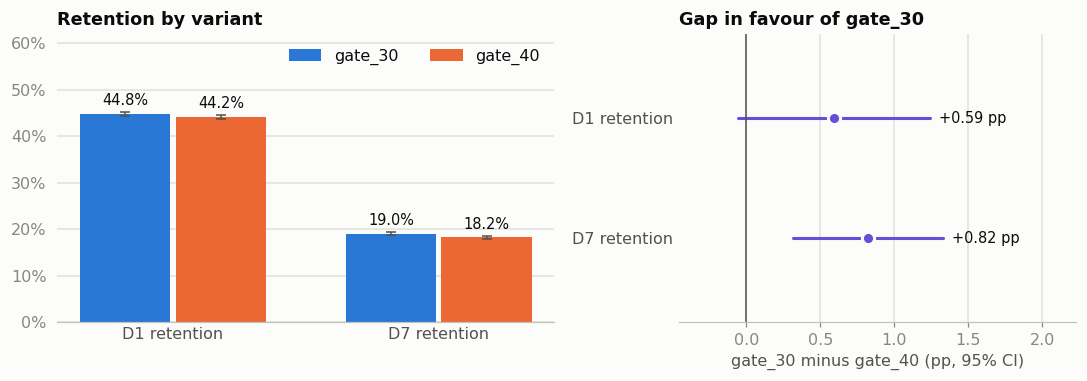

In [6]:
# fig: 01_retention_by_variant
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})

# Left: rates by variant, from a zero baseline, Wilson 95% intervals.
ax = axes[0]
labels = list(cc.METRICS.values())
x = np.arange(len(labels))
w = 0.34
for i, v in enumerate([cc.CONTROL, cc.TREATMENT]):
    rates, lo, hi = [], [], []
    for m in cc.METRICS:
        r = results[m]
        k = "control" if v == cc.CONTROL else "treatment"
        a, b = cc.rate_ci(r[f"x_{k}"], r[f"n_{k}"])
        rates.append(r[f"rate_{k}"]); lo.append(r[f"rate_{k}"] - a); hi.append(b - r[f"rate_{k}"])
    xs = x + (i - 0.5) * (w + 0.02)
    ax.bar(xs, rates, width=w, color=COLORS[v], label=v, zorder=2)
    ax.errorbar(xs, rates, yerr=[lo, hi], fmt="none", ecolor=INK2, elinewidth=1, capsize=3, zorder=3)
    for xx, rr in zip(xs, rates):
        ax.text(xx, rr + 0.012, f"{rr:.1%}", ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_xticks(x, labels)
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("Retention by variant")
ax.legend(loc="upper right", ncols=2)
ax.tick_params(axis="x", colors=INK2, length=0)

# Right: the gap with its 95% CI, against zero.
ax = axes[1]
for j, m in enumerate(cc.METRICS):
    r = results[m]
    y = len(cc.METRICS) - 1 - j
    ax.plot([100*r["ci_low"], 100*r["ci_high"]], [y, y], color=NEUTRAL, lw=2, zorder=2)
    ax.scatter([100*r["diff"]], [y], s=64, color=NEUTRAL, edgecolor="#fcfcfb", linewidth=2, zorder=3)
    ax.text(100*r["ci_high"] + 0.06, y, f"{100*r['diff']:+.2f} pp", va="center", fontsize=9.5, color=INK)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(range(len(cc.METRICS)), list(reversed(labels)))
ax.set_ylim(-0.7, len(cc.METRICS) - 0.3)
lo_ = min(0, min(100*r["ci_low"] for r in results.values()))
hi_ = max(0, max(100*r["ci_high"] for r in results.values()))
ax.set_xlim(lo_ - 0.4, hi_ + 0.9)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", colors=INK2, length=0)
ax.set_xlabel("gate_30 minus gate_40 (pp, 95% CI)")
ax.set_title("Gap in favour of gate_30")
fig.tight_layout()
plt.show()


### Could the imbalance explain the D7 result?

gate_40 has 789 more players than gate_30. The file can't say which players are "surplus", so this bounds the effect by assumption rather than diagnosing it:

- **Surplus players look typical:** the gap stays at +0.82 pp (p = 0.0016).
- **Worst case, none of the 789 extra gate_40 players were retained:** the gap falls to +0.50 pp (95% CI −0.01 to +1.01, p = 0.056).
- **Worst case, 789 gate_30 players went missing and none were retained:** the gap falls to +0.49 pp (95% CI −0.01 to +0.99, p = 0.057).
- **Break-even:** at least 784 of the 789 (99.4%) would have to be non-retained before the gap loses significance. A typical gate_40 player is non-retained 81.8% of the time.

So the imbalance alone is unlikely to overturn the direction of the result, though only an extreme scenario was needed to take it just past the 0.05 line. These scenarios cover a surplus of this size only. A fault that changed *which* players were recorded, without changing the count much, wouldn't show up here.

The second table repeats the retention tests without the one player above 10,000 rounds. D7 stays at +0.82 pp (p = 0.0016) and D1 at +0.59 pp (p = 0.074).

In [7]:
# How far could the 50/50 imbalance move the primary result?
r7 = results["retention_7"]
sens = cc.srm_sensitivity(r7["x_control"], r7["n_control"], r7["x_treatment"], r7["n_treatment"])
scenarios = {"as observed": r7,
             "extras typical, dropped": sens["typical_extras_dropped"],
             "worst case: extras dropped": sens["worst_extras_dropped"],
             "worst case: missing added": sens["worst_missing_added"]}
print(f"imbalance: {sens['excess_players']} players; gap loses significance only if at least "
      f"{sens['breakeven_non_retained']} of them ({sens['breakeven_share']:.1%}) were non-retained "
      f"(typical gate_40 non-retained share: {sens['typical_non_retained_share']:.1%})")
pd.DataFrame({k: {"gate_30": f"{r['rate_control']:.2%}", "gate_40": f"{r['rate_treatment']:.2%}",
                  "gap (pp)": f"{100*r['diff']:+.2f}",
                  "95% CI (pp)": f"[{100*r['ci_low']:+.2f}, {100*r['ci_high']:+.2f}]",
                  "p-value": f"{r['p_value']:.4f}"} for k, r in scenarios.items()}).T


imbalance: 789 players; gap loses significance only if at least 784 of them (99.4%) were non-retained (typical gate_40 non-retained share: 81.8%)


,gate_30,gate_40,gap (pp),95% CI (pp),p-value
as observed,19.02%,18.20%,+0.82,"[+0.31, +1.33]",0.0016
"extras typical, dropped",19.02%,18.20%,+0.82,"[+0.31, +1.33]",0.0016
worst case: extras dropped,19.02%,18.52%,+0.50,"[-0.01, +1.01]",0.0561
worst case: missing added,18.69%,18.20%,+0.49,"[-0.01, +0.99]",0.0566


In [8]:
# The same retention tests without the one player above the outlier cap.
df_capped = df[df["sum_gamerounds"] <= OUTLIER_CAP]
results_capped = {m: cc.compare_metric(df_capped, m) for m in cc.METRICS}
pd.DataFrame([fmt_row(cc.METRICS[m], r) for m, r in results_capped.items()]).set_index("metric")


,gate_30,gate_40,"gap (pp, 30 minus 40)",95% CI (pp),gate_40 vs gate_30,z,p-value
metric,,,,,,,
D1 retention,44.82%,44.23%,+0.59,"[-0.06, +1.24]",-1.3%,1.79,0.0739
D7 retention,19.02%,18.20%,+0.82,"[+0.31, +1.33]",-4.3%,3.16,0.0016


## 4. Bootstrap: a second view with fewer assumptions

A bootstrap re-runs the experiment on resampled copies of the data, here 10,000 times, and needs no normal approximation. It also gives a figure that is easy to read: the share of resamples in which gate_30 retained better.

- **D7:** gate_30 led in 99.9% of resamples (95% interval +0.31 to +1.34 pp).
- **D1:** gate_30 led in 96.5% of resamples (95% interval −0.06 to +1.25 pp).

The intervals agree with section 3, so the z-test's approximation isn't driving the result. The bootstrap uses the same data, so it isn't independent evidence, and it doesn't correct for the SRM.

In [9]:
boot = {m: cc.bootstrap_diff(r["x_control"], r["n_control"], r["x_treatment"], r["n_treatment"],
                             n_boot=10_000, seed=SEED)
        for m, r in results.items()}
boot_summary = {cc.METRICS[m]: cc.summarise_bootstrap(d) for m, d in boot.items()}
pd.DataFrame({
    k: {"mean gap (pp)": f"{100*s['mean']:+.2f}",
        "95% interval (pp)": f"[{100*s['ci_low']:+.2f}, {100*s['ci_high']:+.2f}]",
        "P(gate_30 retains better)": f"{s['prob_control_better']:.1%}"}
    for k, s in boot_summary.items()
}).T


,mean gap (pp),95% interval (pp),P(gate_30 retains better)
D1 retention,+0.59,"[-0.06, +1.25]",96.5%
D7 retention,+0.82,"[+0.31, +1.34]",99.9%


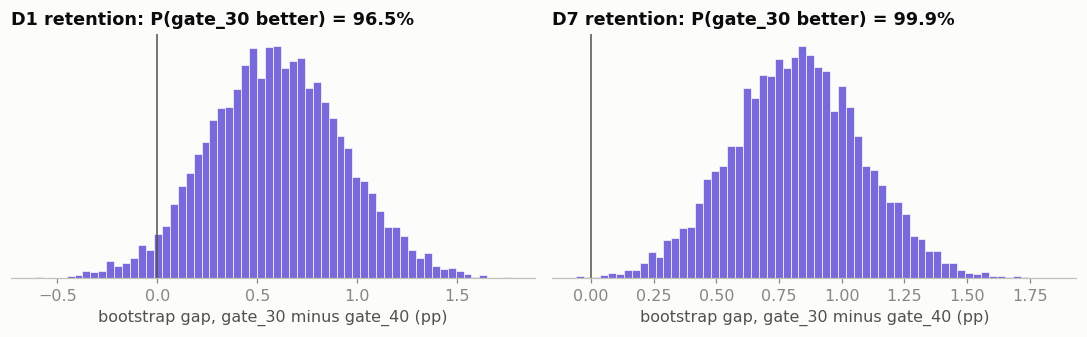

In [10]:
# fig: 02_bootstrap_gap
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=False)
for ax, (m, d) in zip(axes, boot.items()):
    s = boot_summary[cc.METRICS[m]]
    ax.hist(100*d, bins=60, color=NEUTRAL, alpha=0.85, edgecolor="#fcfcfb", linewidth=0.5, zorder=2)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_title(f"{cc.METRICS[m]}: P(gate_30 better) = {s['prob_control_better']:.1%}")
    ax.set_xlabel("bootstrap gap, gate_30 minus gate_40 (pp)")
    ax.set_yticks([])
    ax.grid(False)
fig.tight_layout()
plt.show()


## 5. Power: what this test could and couldn't see

The minimum detectable effect (MDE) is the smallest true gap this sample would catch 80% of the time at alpha = 0.05.

- **D7:** MDE 0.72 pp. The observed 0.82 pp is above it. Power for a gap that size is 89%.
- **D1:** MDE 0.93 pp. The observed 0.59 pp is below it. Power for a gap that size is only 43%, and detecting it reliably would take 111,042 players per arm.

So "D1 isn't significant" doesn't mean D1 is unaffected: a real gap of around 0.6 pp would be missed more often than not. Power at the observed gap is a restatement of the observed result, so the MDE is the number to plan with.

In [11]:
power_rows = []
for m, r in results.items():
    base = r["rate_treatment"]          # gate_40 is the arm being judged
    mde_ = cc.mde(base, r["n_control"], r["n_treatment"])
    power_rows.append({
        "metric": cc.METRICS[m],
        "baseline": f"{base:.2%}",
        "MDE at 80% power (pp)": f"{100*mde_:.2f}",
        "observed gap (pp)": f"{100*r['diff']:+.2f}",
        "power for observed gap": f"{cc.power_for(r['diff'], base, r['n_control'], r['n_treatment']):.0%}",
        "players per arm for 80% power": f"{cc.n_per_arm(base, abs(r['diff'])):,}",
    })
power_table = pd.DataFrame(power_rows).set_index("metric")
power_table


,baseline,MDE at 80% power (pp),observed gap (pp),power for observed gap,players per arm for 80% power
metric,,,,,
D1 retention,44.23%,0.93,+0.59,43%,"111,042"
D7 retention,18.20%,0.72,+0.82,89%,"34,746"


## 6. Engagement: rounds played

`sum_gamerounds` is heavily skewed, so the test is Mann-Whitney, which compares ranks rather than means.

- **All players:** mean 52.46 vs 51.30 rounds, p = 0.0502, and a random gate_30 player out-plays a random gate_40 player with probability 0.504.
- **Without the outlier:** mean 51.34 vs 51.30 rounds, p = 0.0509, and the same 0.504.

One gate_30 player logged 49,854 rounds in 14 days, which isn't human play. Removing that player erases almost all of the gap in means but leaves the rank test essentially unchanged, which is why a rank test is the right tool here. Engagement shows no significant difference either way, with p just above 0.05.

**Rounds aren't levels.** Failed attempts count as rounds, so N rounds doesn't mean level N, and the 30 and 40 lines on the chart below mark rounds rather than gates. A player with fewer than 30 rounds can't have reached either gate: that is 62.7% of gate_30 and 63.5% of gate_40.

In [12]:
cc.rounds_summary(df).round(1)


,players,mean,median,p75,p90,p99,max
version,,,,,,,
gate_30,44700,52.5,17.0,50.0,135.0,493.0,49854
gate_40,45489,51.3,16.0,52.0,134.0,492.1,2640


In [13]:
rt_all = cc.rounds_test(df)
rt_cap = cc.rounds_test(df, cap=OUTLIER_CAP)
for name, rt in [("all players", rt_all), (f"rounds <= {OUTLIER_CAP:,}", rt_cap)]:
    print(f"{name:>18}: dropped {rt['players_dropped']}, mean {rt['mean_control']:.1f} vs {rt['mean_treatment']:.1f}, "
          f"Mann-Whitney p = {rt['p_value']:.3f}, P(gate_30 player plays more) = {rt['prob_control_plays_more']:.3f}")


       all players: dropped 0, mean 52.5 vs 51.3, Mann-Whitney p = 0.050, P(gate_30 player plays more) = 0.504
  rounds <= 10,000: dropped 1, mean 51.3 vs 51.3, Mann-Whitney p = 0.051, P(gate_30 player plays more) = 0.504


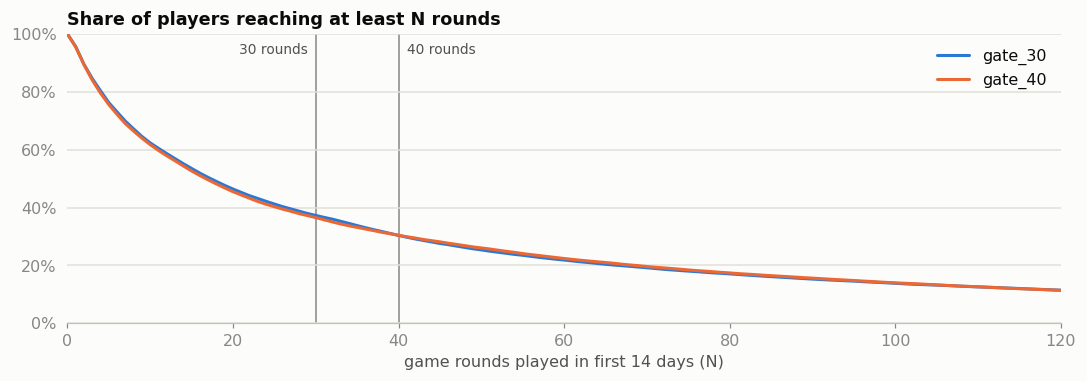

In [14]:
# fig: 03_rounds_survival
# Share of players who played at least N rounds in their first 14 days.
N = np.arange(0, 121)
fig, ax = plt.subplots(figsize=(10, 3.6))
for v in [cc.CONTROL, cc.TREATMENT]:
    r = np.sort(df.loc[df["version"] == v, "sum_gamerounds"].to_numpy())
    still = 1 - np.searchsorted(r, N, side="left") / len(r)
    ax.plot(N, still, color=COLORS[v], label=v)
for g, ha, dx in ((30, "right", -1), (40, "left", 1)):
    ax.axvline(g, color=MUTED, lw=1, zorder=0)
    ax.text(g + dx, 0.93, f"{g} rounds", color=INK2, fontsize=9, ha=ha)
ax.set_ylim(0, 1)
ax.set_xlim(0, 120)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_xlabel("game rounds played in first 14 days (N)")
ax.set_title("Share of players reaching at least N rounds")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


## 7. Segments: descriptive only

**Caveat: these aren't causal.** Rounds are measured after assignment, so the gate itself can move players between buckets, and the players inside a bucket are no longer comparable across arms. Only the all-player comparison above is a clean experiment.

The mix-shift test confirms that the arms are spread differently across buckets (chi-square = 25.04, 4 degrees of freedom, p = 0.00005). The 30–39 bucket holds 6.9% of gate_30 and 6.1% of gate_40.

The largest gap is in the 40–99 bucket: D7 of 32.9% vs 29.4%, a gap of +3.51 pp (95% CI +2.02 to +5.00). The other four buckets have no significant gap. That pattern suggests where to look next, but it doesn't show that the effect sits in those players.

In [15]:
seg7 = cc.segment_table(df, "retention_7")
seg1 = cc.segment_table(df, "retention_1")
mix = cc.mix_shift_test(df)
print(f"Did the gate change how far players got? chi-square = {mix['chi2']:.1f}, "
      f"dof = {mix['dof']}, p = {mix['p_value']:.4f}")
show = seg7.assign(
    **{"share of gate_30": seg7.share_control.map("{:.1%}".format),
       "share of gate_40": seg7.share_treatment.map("{:.1%}".format),
       "D7 gate_30": seg7.rate_control.map("{:.1%}".format),
       "D7 gate_40": seg7.rate_treatment.map("{:.1%}".format),
       "gap (pp)": (100*seg7["diff"]).map("{:+.2f}".format),
       "95% CI (pp)": [f"[{100*a:+.2f}, {100*b:+.2f}]" for a, b in zip(seg7.ci_low, seg7.ci_high)],
       "p-value": seg7.p_value.map("{:.4f}".format)}
)
show.set_index("segment")[["players_control", "players_treatment", "share of gate_30", "share of gate_40",
                           "D7 gate_30", "D7 gate_40", "gap (pp)", "95% CI (pp)", "p-value"]]


Did the gate change how far players got? chi-square = 25.0, dof = 4, p = 0.0000


,players_control,players_treatment,share of gate_30,share of gate_40,D7 gate_30,D7 gate_40,gap (pp),95% CI (pp),p-value
segment,,,,,,,,,
0 rounds,1937,2057,4.3%,4.5%,0.8%,0.6%,+0.19,"[-0.33, +0.72]",0.4704
1–29,26107,26819,58.4%,59.0%,4.5%,4.2%,+0.33,"[-0.02, +0.68]",0.0638
30–39,3090,2786,6.9%,6.1%,15.7%,15.7%,+0.04,"[-1.82, +1.91]",0.9643
40–99,7398,7479,16.6%,16.4%,32.9%,29.4%,+3.51,"[+2.02, +5.00]",0.0000
100+,6168,6348,13.8%,14.0%,71.1%,71.0%,+0.11,"[-1.48, +1.70]",0.8910


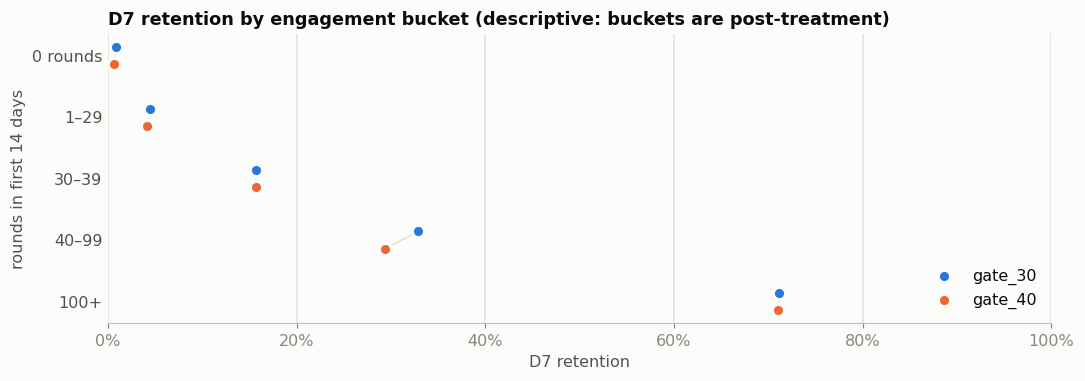

In [16]:
# fig: 04_d7_by_engagement_bucket
fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(seg7))[::-1]
for v, col, off in [(cc.CONTROL, "rate_control", 0.14), (cc.TREATMENT, "rate_treatment", -0.14)]:
    ax.scatter(seg7[col], y + off, s=64, color=COLORS[v], edgecolor="#fcfcfb", linewidth=2, zorder=3, label=v)
for yy, a, b in zip(y, seg7.rate_control, seg7.rate_treatment):
    ax.plot([a, b], [yy + 0.14, yy - 0.14], color=GRID, lw=1, zorder=1)
ax.set_yticks(y, seg7.segment)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", colors=INK2, length=0)
ax.set_xlabel("D7 retention")
ax.set_ylabel("rounds in first 14 days")
ax.set_title("D7 retention by engagement bucket (descriptive: buckets are post-treatment)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


## 8. Outputs

Results are saved to `out/results.json` and `out/segments_*.csv` for the SQL and BI layer.

In [17]:
import os
os.makedirs("out", exist_ok=True)

def clean(o):
    if isinstance(o, dict):
        return {k: clean(v) for k, v in o.items()}
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

facts = clean({
    "checks": checks,
    "srm": srm,
    "results": results,
    "bootstrap": boot_summary,
    "power": {cc.METRICS[m]: {
        "mde": cc.mde(r["rate_treatment"], r["n_control"], r["n_treatment"]),
        "power_observed": cc.power_for(r["diff"], r["rate_treatment"], r["n_control"], r["n_treatment"]),
        "n_per_arm_for_observed": cc.n_per_arm(r["rate_treatment"], abs(r["diff"]))}
        for m, r in results.items()},
    "srm_sensitivity_d7": sens,
    "results_without_outlier": results_capped,
    "under_30_rounds": {
        "players_control": int(seg7.players_control[:2].sum()),
        "players_treatment": int(seg7.players_treatment[:2].sum()),
        "share_control": float(seg7.share_control[:2].sum()),
        "share_treatment": float(seg7.share_treatment[:2].sum())},
    "per_100k_installs_d7": {
        "players_lost": 100_000 * r7["diff"],
        "players_lost_ci_low": 100_000 * r7["ci_low"],
        "players_lost_ci_high": 100_000 * r7["ci_high"]},
    "next_experiments": {
        "baseline_d7_gate_30": r7["rate_control"],
        "n_per_arm_for_observed_gap": cc.n_per_arm(r7["rate_control"], abs(r7["diff"])),
        "planning_gap_small": 0.005,
        "n_per_arm_for_small_gap": cc.n_per_arm(r7["rate_control"], 0.005)},
    "rounds": {"all": rt_all, "capped": rt_cap,
               "summary": cc.rounds_summary(df).reset_index().to_dict(orient="records")},
    "mix_shift": {k: v for k, v in mix.items() if k != "table"},
    "mix_table": mix["table"].reset_index().astype({"sum_gamerounds": str}).to_dict(orient="records"),
    "segments_d7": seg7.to_dict(orient="records"),
    "segments_d1": seg1.to_dict(orient="records"),
})
with open("out/results.json", "w") as f:
    json.dump(facts, f, indent=2, default=float)
seg7.to_csv("out/segments_d7.csv", index=False)
seg1.to_csv("out/segments_d1.csv", index=False)
print("saved out/results.json, out/segments_d7.csv, out/segments_d1.csv")


saved out/results.json, out/segments_d7.csv, out/segments_d1.csv


## 9. Conclusion

**Recommendation: keep the first gate at level 30.** gate_40 is significantly worse on D7 under the pre-set rule, and the result holds without the outlier. It survives every imbalance scenario here except near-total non-retention among the surplus players.

**Before acting:** investigate the SRM in the assignment and logging pipeline. Fix it, or at least explain it, before running any follow-up on the same system.

**Next experiment** (full plans in `case_study.md`): compare a level 25 gate with level 30, and test a shorter wait at level 30, both with revenue logged.

**Limitations**

- No revenue or in-app purchase data, so the monetisation side of the gate is unmeasured.
- Rounds aren't levels, so the file can't show who actually reached a gate.
- Rounds are post-treatment, so the segment view is descriptive only.
- The SRM is unexplained, and the file has no dates or device data to diagnose it.
- One player's 49,854 rounds isn't human play; results are shown with and without that player.
- D1 was underpowered for a gap of the observed size.
- Results cover early retention (D1, D7) and 14 days of play, not long-term value.